In [10]:
from math import floor

import numpy as np
import pandas as pd

T = 24  # input sequence length
H = 8  # forecasting horizon

N = 43824  # total time-series observations 2021-01-01 00:00:00 - 2025-12-31 23:00:00

In [11]:
values = np.arange(N)

timestamps = pd.date_range(
    start="2021-01-01 00:00:00",
    periods=N,
    freq="h"
)

df = pd.DataFrame({
    "Time": timestamps,
    "Value": values
})

df.head(10)

,Time,Value
0,2021-01-01 00:00:00,0
1,2021-01-01 01:00:00,1
2,2021-01-01 02:00:00,2
3,2021-01-01 03:00:00,3
4,2021-01-01 04:00:00,4
5,2021-01-01 05:00:00,5
6,2021-01-01 06:00:00,6
7,2021-01-01 07:00:00,7
8,2021-01-01 08:00:00,8
9,2021-01-01 09:00:00,9


In [53]:
def make_windows_simple(values, T, H):
    instances = ((len(values) - T - H) // H) + 1

    X = np.stack([
        values[i * H : i * H + T]
        for i in range(instances)
    ])

    Y = np.stack([
        values[i * H + T : i * H + T + H]
        for i in range(instances)
    ])

    return X, Y

In [54]:
X, Y = make_windows_simple(values, T, H)

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (5475, 24)
Y shape: (5475, 8)


In [20]:
win_count = 0
for i in range(len(X)):
    if win_count < 10:
        print(f"\nWindow {i}")
        print("Input X:", X[i])
        print("Target Y:", Y[i])
        win_count += 1
    else:
        break


Window 0
Input X: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
Target Y: [24 25 26 27 28 29 30 31]

Window 1
Input X: [ 8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31]
Target Y: [32 33 34 35 36 37 38 39]

Window 2
Input X: [16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39]
Target Y: [40 41 42 43 44 45 46 47]

Window 3
Input X: [24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47]
Target Y: [48 49 50 51 52 53 54 55]

Window 4
Input X: [32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55]
Target Y: [56 57 58 59 60 61 62 63]

Window 5
Input X: [40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63]
Target Y: [64 65 66 67 68 69 70 71]

Window 6
Input X: [48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71]
Target Y: [72 73 74 75 76 77 78 79]

Window 7
Input X: [56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79]
Targ

In [61]:
train_instances = int(X.shape[0] * 0.70)
val_instances = int(X.shape[0] * 0.15)
test_instances = int(X.shape[0] * 0.15)

print("train:", train_instances)
print("val:", val_instances)
print("test:", test_instances)

X_train = X[:train_instances]
Y_train = Y[:train_instances]
X_val = X[train_instances:train_instances+val_instances]
Y_val = Y[train_instances:train_instances+val_instances]
X_test = X[train_instances+val_instances:X.shape[0]]
Y_test = Y[train_instances+val_instances:X.shape[0]]

train: 3832
val: 821
test: 821


In [91]:
train_s = T
train_e = train_s + train_instances * H
val_s = train_e
val_e = val_s + val_instances * H
test_s = val_e
test_e = test_s + test_instances * H

print("train_s:", train_s)
print("val_s:", val_s)
print("test_s:", test_s)

print("train_e:", train_e)
print("val_e:", val_e)
print("test_e", test_e)

train_s: 24
val_s: 30680
test_s: 37248
train_e: 30680
val_e: 37248
test_e 43816


In [96]:
timestamps_np = np.array(timestamps)
test_start = train_instances+val_instances

start = (
    (train_instances+val_instances + np.arange(len(X_test)))[:, None] * H
)

future_indices = start + T + np.arange(H)

future_times = timestamps_np[future_indices]

print("Future indices:")
print(future_indices)

print("\nFuture timestamps:")
print(future_times)

Future indices:
[[37248 37249 37250 ... 37253 37254 37255]
 [37256 37257 37258 ... 37261 37262 37263]
 [37264 37265 37266 ... 37269 37270 37271]
 ...
 [43800 43801 43802 ... 43805 43806 43807]
 [43808 43809 43810 ... 43813 43814 43815]
 [43816 43817 43818 ... 43821 43822 43823]]

Future timestamps:
[['2025-04-02T00:00:00.000000' '2025-04-02T01:00:00.000000'
  '2025-04-02T02:00:00.000000' ... '2025-04-02T05:00:00.000000'
  '2025-04-02T06:00:00.000000' '2025-04-02T07:00:00.000000']
 ['2025-04-02T08:00:00.000000' '2025-04-02T09:00:00.000000'
  '2025-04-02T10:00:00.000000' ... '2025-04-02T13:00:00.000000'
  '2025-04-02T14:00:00.000000' '2025-04-02T15:00:00.000000']
 ['2025-04-02T16:00:00.000000' '2025-04-02T17:00:00.000000'
  '2025-04-02T18:00:00.000000' ... '2025-04-02T21:00:00.000000'
  '2025-04-02T22:00:00.000000' '2025-04-02T23:00:00.000000']
 ...
 ['2025-12-31T00:00:00.000000' '2025-12-31T01:00:00.000000'
  '2025-12-31T02:00:00.000000' ... '2025-12-31T05:00:00.000000'
  '2025-12-31T06

In [97]:
for i in range(len(X_test)):
    window_idx = test_start + i

    input_start = window_idx * H
    input_end = input_start + T

    target_start = input_start + T
    target_end = target_start + H

    actual_input_indices = np.arange(input_start, input_end)
    actual_target_indices = np.arange(target_start, target_end)

    print(f"\nTest window {i}")
    print("Input indices:", actual_input_indices)
    print("Input values :", X_test[i])

    print("Target indices:", actual_target_indices)
    print("Target values :", Y_test[i])

    print("Target timestamps:", future_times[i])


Test window 0
Input indices: [37224 37225 37226 37227 37228 37229 37230 37231 37232 37233 37234 37235
 37236 37237 37238 37239 37240 37241 37242 37243 37244 37245 37246 37247]
Input values : [37224 37225 37226 37227 37228 37229 37230 37231 37232 37233 37234 37235
 37236 37237 37238 37239 37240 37241 37242 37243 37244 37245 37246 37247]
Target indices: [37248 37249 37250 37251 37252 37253 37254 37255]
Target values : [37248 37249 37250 37251 37252 37253 37254 37255]
Target timestamps: ['2025-04-02T00:00:00.000000' '2025-04-02T01:00:00.000000'
 '2025-04-02T02:00:00.000000' '2025-04-02T03:00:00.000000'
 '2025-04-02T04:00:00.000000' '2025-04-02T05:00:00.000000'
 '2025-04-02T06:00:00.000000' '2025-04-02T07:00:00.000000']

Test window 1
Input indices: [37232 37233 37234 37235 37236 37237 37238 37239 37240 37241 37242 37243
 37244 37245 37246 37247 37248 37249 37250 37251 37252 37253 37254 37255]
Input values : [37232 37233 37234 37235 37236 37237 37238 37239 37240 37241 37242 37243
 37244 3

In [99]:
assert np.array_equal(
    Y_test,
    values[future_indices]
), "Target values and future indices do not match!"

assert np.array_equal(
    future_times,
    timestamps_np[future_indices]
), "Timestamp mismatch!"

print("All target values and timestamps are aligned correctly.")

All target values and timestamps are aligned correctly.


In [100]:
flat_indices = future_indices.flatten()

print("Forecast indices:", flat_indices)
print("Unique indices :", np.unique(flat_indices))

assert len(flat_indices) == len(np.unique(flat_indices)), \
    "Duplicate forecast timestamps found!"

assert np.all(np.diff(flat_indices) == 1), \
    "There is a gap in forecast timestamps!"

print("No duplicates or gaps between forecast timestamps.")

Forecast indices: [37248 37249 37250 ... 43821 43822 43823]
Unique indices : [37248 37249 37250 ... 43821 43822 43823]
No duplicates or gaps between forecast timestamps.


In [103]:
def verify_windows_and_timestamps(values, timestamps, T, H, test_start=0):
    X, Y = make_windows_simple(values, T, H)

    test_X = X[test_start:]
    test_Y = Y[test_start:]

    starts = np.arange(test_start, test_start + len(test_X)) * H
    future_indices = starts[:, None] + T + np.arange(H)

    future_times = timestamps[future_indices]

    # Verify targets
    assert np.array_equal(test_Y, values[future_indices])

    # Verify timestamps
    assert np.array_equal(future_times, timestamps[future_indices])

    # Verify consecutive forecast timestamps
    flattened = future_indices.flatten()

    assert np.all(np.diff(flattened) == 1), \
        "Forecast indices contain gaps or overlaps"

    print(
        f"PASS | T={T:2d} | H={H:2d} | "
        f"Test windows={len(test_X):3d} | "
        f"First forecast index={future_indices[0, 0]} | "
        f"Last forecast index={future_indices[-1, -1]}"
    )


for T_test, H_test in [
    (4, 1),
    (4, 2),
    (4, 3),
    (4, 4),
    (5, 2),
    (8, 4),
    (12, 6),
    (24, 8),
]:
    verify_windows_and_timestamps(
        values=values,
        timestamps=timestamps_np,
        T=T_test,
        H=H_test,
        test_start=3
    )

PASS | T= 4 | H= 1 | Test windows=43817 | First forecast index=7 | Last forecast index=43823
PASS | T= 4 | H= 2 | Test windows=21907 | First forecast index=10 | Last forecast index=43823
PASS | T= 4 | H= 3 | Test windows=14603 | First forecast index=13 | Last forecast index=43821
PASS | T= 4 | H= 4 | Test windows=10952 | First forecast index=16 | Last forecast index=43823
PASS | T= 5 | H= 2 | Test windows=21906 | First forecast index=11 | Last forecast index=43822
PASS | T= 8 | H= 4 | Test windows=10951 | First forecast index=20 | Last forecast index=43823
PASS | T=12 | H= 6 | Test windows=7299 | First forecast index=30 | Last forecast index=43823
PASS | T=24 | H= 8 | Test windows=5472 | First forecast index=48 | Last forecast index=43823


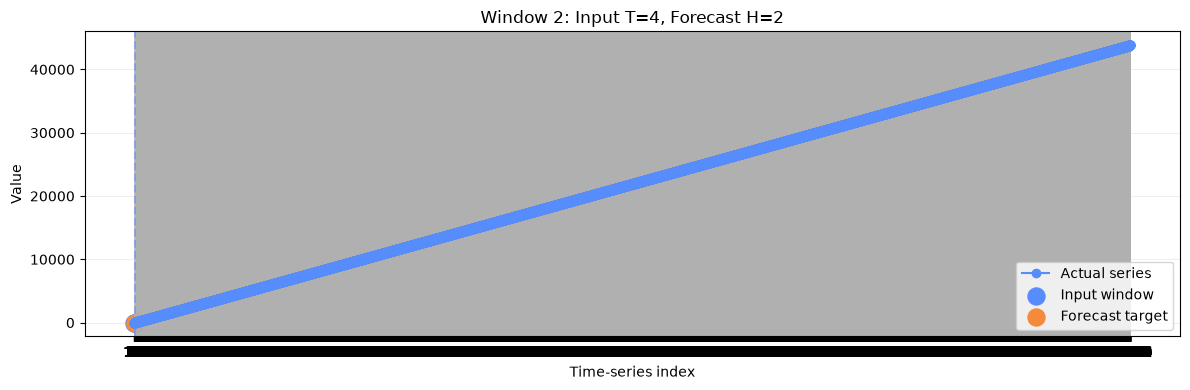

In [104]:
import matplotlib.pyplot as plt

T, H = 4, 2
X, Y = make_windows_simple(values, T, H)

window_number = 2

input_indices = np.arange(window_number * H, window_number * H + T)
target_indices = np.arange(window_number * H + T, window_number * H + T + H)

plt.figure(figsize=(12, 4))

plt.plot(values, marker="o", label="Actual series")
plt.scatter(input_indices, values[input_indices], s=150, label="Input window")
plt.scatter(target_indices, values[target_indices], s=150, label="Forecast target")

plt.axvline(input_indices[-1], linestyle="--", alpha=0.5)

plt.xticks(np.arange(len(values)))
plt.xlabel("Time-series index")
plt.ylabel("Value")
plt.title(f"Window {window_number}: Input T={T}, Forecast H={H}")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()